<a href="https://colab.research.google.com/github/bitwise-arnesh/ml-lab-experiments/blob/feature%2Fexperiments-3-4/Experiment-4/Experiment-4-Drug-Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML Lab Experiment 4

## Drug Prediction using Decision Tree

### Objective

Using the Decision Tree algorithm, predict which drug should be given to a patient among Drug X, Drug Y, and Drug C, and calculate the accuracy of the Decision Tree classifier.

First five rows:
   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY

Dataset shape: (200, 6)

Column names:
Index(['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug'], dtype='object')

Missing values:
Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

Training samples: 140
Testing samples: 60

Decision Tree model trained successfully.

Decision Tree Accuracy: 1.0
Accuracy Percentage: 100.0 %

Actual vs Predicted:
   Actual Drug Predicted Drug
0        drugX          drugX
1        drugY          drugY
2        drugX          drugX
3        drugC          drugC
4        drugY          drugY
5        drugY          drugY
6        drugY          drugY
7        drugX          drugX
8        drugA 

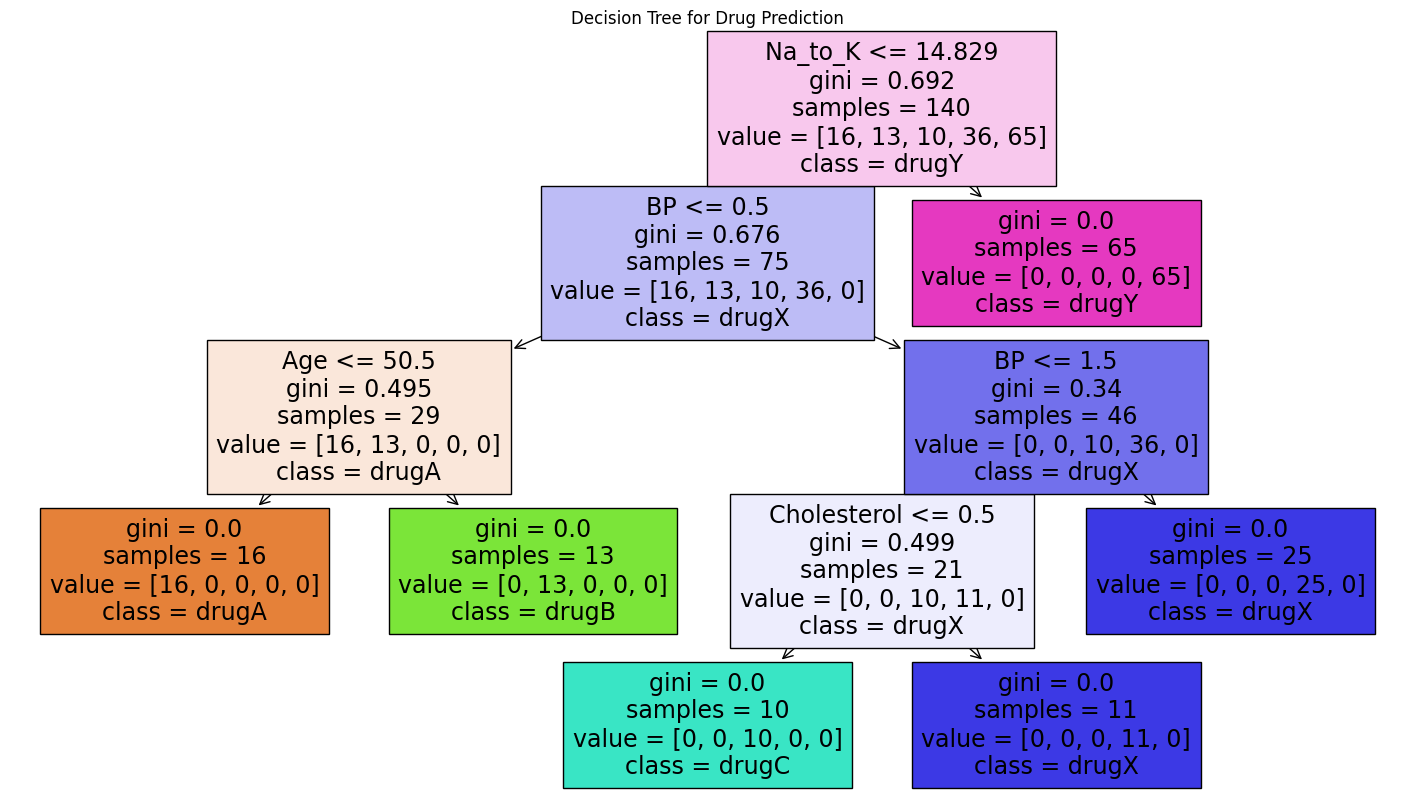

In [ ]:
# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


# Load the dataset

df = pd.read_csv("drug - drug.csv")

# Display the first five rows

print("First five rows:")
print(df.head())


# Display dataset information

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())


# Encode categorical input features

label_encoder_sex = LabelEncoder()
label_encoder_bp = LabelEncoder()
label_encoder_cholesterol = LabelEncoder()

df["Sex"] = label_encoder_sex.fit_transform(df["Sex"])
df["BP"] = label_encoder_bp.fit_transform(df["BP"])
df["Cholesterol"] = label_encoder_cholesterol.fit_transform(df["Cholesterol"])


# Encode the target variable

label_encoder_drug = LabelEncoder()
df["Drug"] = label_encoder_drug.fit_transform(df["Drug"])


# Separate input features and target variable

X = df[["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]]
y = df["Drug"]


# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


# Display the number of training and testing samples

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# Create the Decision Tree classifier

model = DecisionTreeClassifier(random_state=42)


# Train the Decision Tree

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully.")


# Predict the drug for the testing data

y_pred = model.predict(X_test)


# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\nDecision Tree Accuracy:", accuracy)


# Display accuracy as percentage

print("Accuracy Percentage:", accuracy * 100, "%")


# Display actual and predicted drug values

actual_drugs = label_encoder_drug.inverse_transform(y_test)
predicted_drugs = label_encoder_drug.inverse_transform(y_pred)

results = pd.DataFrame({
    "Actual Drug": actual_drugs,
    "Predicted Drug": predicted_drugs
})

print("\nActual vs Predicted:")
print(results)


# Predict the drug for a new patient

# Example patient:
# Age = 35
# Sex = F
# BP = HIGH
# Cholesterol = NORMAL
# Na_to_K = 15.0

new_patient = pd.DataFrame({
    "Age": [35],
    "Sex": [label_encoder_sex.transform(["F"])[0]],
    "BP": [label_encoder_bp.transform(["HIGH"])[0]],
    "Cholesterol": [label_encoder_cholesterol.transform(["NORMAL"])[0]],
    "Na_to_K": [15.0]
})

prediction = model.predict(new_patient)

predicted_drug = label_encoder_drug.inverse_transform(prediction)

print("\nPredicted drug for the new patient:", predicted_drug[0])


# Plot the Decision Tree

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=label_encoder_drug.classes_,
    filled=True
)

plt.title("Decision Tree for Drug Prediction")
plt.show()